<a href="https://colab.research.google.com/github/karquiza/task-delay-risk-predictor/blob/ML_Model/notebooks/ML_Model_for_PM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

=== Logistic_Regression (TEST - Seed 26, Thresh=0.4052) ===
              precision    recall  f1-score   support

 On_Time (0)     0.8824    0.1515    0.2586       198
    Late (1)     0.3171    0.9512    0.4756        82

    accuracy                         0.3857       280
   macro avg     0.5997    0.5514    0.3671       280
weighted avg     0.7168    0.3857    0.3222       280

--- Logistic_Regression (TEST - Seed 26, Thresh=0.4052) Confusion Matrix (Counts) ---
                 Pred: On_Time  Pred: Late
Actual: On_Time             30         168
Actual: Late                 4          78
--- Logistic_Regression (TEST - Seed 26, Thresh=0.4052) Confusion Matrix (Row % / Recall) ---
                 Pred: On_Time (%)  Pred: Late (%)
Actual: On_Time               15.2            84.8
Actual: Late                   4.9            95.1

=== Logistic_Regress

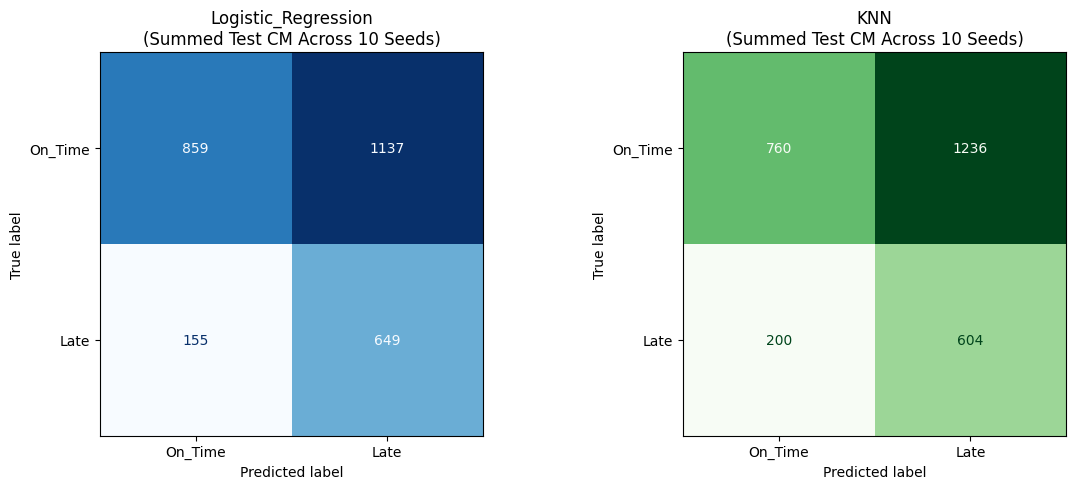


=== Comparison: v2_comparison - Logistic Regression (TEST - Seed 26) ===
              precision    recall  f1-score   support

 On_Time (0)     0.6696    0.6410    0.6550       117
    Late (1)     0.7500    0.7730    0.7613       163

    accuracy                         0.7179       280
   macro avg     0.7098    0.7070    0.7082       280
weighted avg     0.7164    0.7179    0.7169       280

--- Comparison: v2_comparison - Logistic Regression (TEST - Seed 26) Confusion Matrix (Counts) ---
                 Pred: On_Time  Pred: Late
Actual: On_Time             75          42
Actual: Late                37         126
--- Comparison: v2_comparison - Logistic Regression (TEST - Seed 26) Confusion Matrix (Row % / Recall) ---
                 Pred: On_Time (%)  Pred: Late (%)
Actual: On_Time               64.1            35.9
Actual: Late                  22.7            77.3

=== Final 10-Seed & Comparison Results ===
      Dataset               Model  Seed    AUC  Threshold  Recall  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

try:
    import google.colab
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/MAI104 Group Project"
else:
    PROJECT_DIR = "."

DATA_DIR = os.path.join(PROJECT_DIR, "data")
SPLITS_DIR = os.path.join(DATA_DIR, "splits")

# 1. Load V3 Data & Define Set B Features + Binary Target
df_v3 = pd.read_csv(os.path.join(DATA_DIR, "Synthetic_Data_V3.csv"))

num_cols = [
    "Story_Points",
    "Assignee_Active_Workload_SP",
    "Assignee_Experience_Years",
    "Upstream_Delay_Days",
    "Num_Predecessors",
    "Open_Predecessors",
    "Slack_Days",
]
bin_cols = ["Is_Milestone_Gate", "External_Dependency"]
features = num_cols + bin_cols

df_v3["Late"] = (df_v3["Risk_Outcome"] != "On_Time").astype(int)

# 2. Helper Functions for Splits, Thresholding, Risk Tiers, and Metrics
def load_split(df, seed):
    """Loads split_assignments_seed{seed}.csv and splits df into train, val, and test."""
    split_path = os.path.join(SPLITS_DIR, f"split_assignments_seed{seed}.csv")
    split_df = pd.read_csv(split_path)

    id_col = [c for c in split_df.columns if "id" in c.lower()][0]
    split_col = [c for c in split_df.columns if c != id_col][0]

    split_map = split_df.set_index(id_col)[split_col].astype(str).str.lower()
    assigned = df[id_col].map(split_map)

    train_df = df[assigned.str.startswith("train", na=False)]
    val_df = df[assigned.str.startswith("val", na=False)]
    test_df = df[assigned.str.startswith("test", na=False)]

    return (
        train_df[features], train_df["Late"].values,
        val_df[features], val_df["Late"].values,
        test_df[features], test_df["Late"].values,
    )

def find_val_threshold(y_val, val_probs, target_recall=0.70):
    """Finds the highest probability threshold that achieves >= target_recall on validation."""
    thresholds = np.sort(np.unique(val_probs))[::-1]
    best_thresh = 0.0
    for t in thresholds:
        preds = (val_probs >= t).astype(int)
        if recall_score(y_val, preds, zero_division=0) >= target_recall:
            best_thresh = float(t)
            break
    return best_thresh

def assign_risk_tier(prob, high_thresh):
    """Maps predicted P(Late) into Low, Medium, and High delay risk tiers."""
    med_thresh = high_thresh * 0.5
    if prob >= high_thresh:
        return "High"
    elif prob >= med_thresh:
        return "Medium"
    else:
        return "Low"

def evaluate_predictions(y_true, probs, threshold, checklist_recall=None):
    """Computes AUC, recall, precision, precision at checklist recall, and top 20% late share."""
    auc = roc_auc_score(y_true, probs)
    preds = (probs >= threshold).astype(int)
    rec = recall_score(y_true, preds, zero_division=0)
    prec = precision_score(y_true, preds, zero_division=0)

    target_r = checklist_recall if checklist_recall is not None else 0.70
    prec_at_checklist = np.nan
    for t in np.sort(np.unique(probs))[::-1]:
        p_tmp = (probs >= t).astype(int)
        if recall_score(y_true, p_tmp, zero_division=0) >= target_r:
            prec_at_checklist = precision_score(y_true, p_tmp, zero_division=0)
            break

    top_k = max(1, int(np.ceil(0.20 * len(y_true))))
    top_indices = np.argsort(probs)[::-1][:top_k]
    top_20_late_share = float(np.mean(y_true[top_indices]))

    return {
        "AUC": round(auc, 4),
        "Threshold": round(threshold, 4),
        "Recall": round(rec, 4),
        "Precision": round(prec, 4),
        "Precision_at_Checklist_Recall": round(prec_at_checklist, 4) if not np.isnan(prec_at_checklist) else np.nan,
        "Top_20pct_Late_Share": round(top_20_late_share, 4),
    }

def show_detailed_cm(y_true, y_pred, title):
    """Prints classification report, raw counts, and row % recall confusion matrix."""
    target_names = ["On_Time (0)", "Late (1)"]
    print(f"\n=== {title} ===")
    print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    cm_df = pd.DataFrame(
        cm,
        index=["Actual: On_Time", "Actual: Late"],
        columns=["Pred: On_Time", "Pred: Late"],
    )
    print(f"--- {title} Confusion Matrix (Counts) ---")
    print(cm_df)

    cm_norm = confusion_matrix(y_true, y_pred, labels=[0, 1], normalize="true")
    cm_norm_df = pd.DataFrame(
        (cm_norm * 100).round(1),
        index=["Actual: On_Time", "Actual: Late"],
        columns=["Pred: On_Time (%)", "Pred: Late (%)"],
    )
    print(f"--- {title} Confusion Matrix (Row % / Recall) ---")
    print(cm_norm_df)
    return cm

def build_models():
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("bin", "passthrough", bin_cols),
    ])
    return {
        "Logistic_Regression": Pipeline([
            ("prep", preprocessor),
            ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
        ]),
        "KNN": Pipeline([
            ("prep", preprocessor),
            ("clf", KNeighborsClassifier(n_neighbors=15, weights="distance")),
        ]),
    }

# 3. Run Logistic Regression and KNN Across All 10 Seeds
seeds = [26, 10, 16, 21, 30, 42, 50, 55, 101, 201]
results_rows = []
CHECKLIST_RECALL = None

agg_cms = {"Logistic_Regression": np.zeros((2, 2), dtype=int), "KNN": np.zeros((2, 2), dtype=int)}
cmaps = {"Logistic_Regression": "Blues", "KNN": "Greens"}

for seed in seeds:
    X_tr, y_tr, X_va, y_va, X_te, y_te = load_split(df_v3, seed=seed)
    models = build_models()

    for name, model in models.items():
        model.fit(X_tr, y_tr)

        # Tune threshold strictly on Validation
        va_probs = model.predict_proba(X_va)[:, 1]
        thresh = find_val_threshold(y_va, va_probs, target_recall=0.70)

        # Evaluate on Test unchanged
        te_probs = model.predict_proba(X_te)[:, 1]
        te_preds = (te_probs >= thresh).astype(int)
        metrics = evaluate_predictions(y_te, te_probs, thresh, checklist_recall=CHECKLIST_RECALL)

        results_rows.append({"Dataset": "v3_main", "Model": name, "Seed": seed, **metrics})
        agg_cms[name] += confusion_matrix(y_te, te_preds, labels=[0, 1])

        # Print classification report, CM, and Low/Medium/High delay risk tiers for Seed 26
        if seed == 26:
            show_detailed_cm(y_te, te_preds, f"{name} (TEST - Seed 26, Thresh={thresh:.4f})")

            tiers = [assign_risk_tier(p, thresh) for p in te_probs]
            risk_preview = pd.DataFrame({
                "Actual_Late": y_te,
                "P(On_Time)": (1 - te_probs).round(4),
                "P(Late)": te_probs.round(4),
                "Delay_Risk_Tier": tiers,
            })

            print(f"\n=== {name}: Delay Risk Tier Distribution (Seed 26 Test) ===")
            summary = risk_preview.groupby("Delay_Risk_Tier").agg(
                Task_Count=("Actual_Late", "count"),
                Actual_Late_Rate=("Actual_Late", "mean"),
                Avg_Delay_Prob=("P(Late)", "mean"),
            ).reindex(["Low", "Medium", "High"])
            print(summary.round(4))

            print(f"\nSample Task Delay Probabilities ({name} - Seed 26 Test):")
            print(risk_preview.head(10).to_string(index=False))

# Plot Side-by-Side Aggregated 10-Seed Test Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, cm) in zip(axes, agg_cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["On_Time", "Late"]).plot(
        ax=ax, cmap=cmaps[name], colorbar=False
    )
    ax.set_title(f"{name}\n(Summed Test CM Across 10 Seeds)")
plt.tight_layout()
plt.show()

# 4. Comparison Runs (Logistic Regression Only: V2 and V3 Rated at Task Start)
comparison_datasets = {}

v2_path = os.path.join(DATA_DIR, "Synthetic Data V2.csv")
if not os.path.exists(v2_path):
    v2_path = os.path.join(DATA_DIR, "Synthetic_Data_V2.csv")
if os.path.exists(v2_path):
    df_v2 = pd.read_csv(v2_path)
    df_v2["Late"] = (df_v2["Risk_Outcome"] != "On_Time").astype(int)
    for col in features:
        if col not in df_v2.columns:
            df_v2[col] = 0
    comparison_datasets["v2_comparison"] = df_v2

v3_start_path = os.path.join(DATA_DIR, "Synthetic_Data_V3_start.csv")
gen_script = os.path.join(PROJECT_DIR, "generate_synthetic_v3.py")
if not os.path.exists(v3_start_path) and os.path.exists(gen_script):
    subprocess.run(["python", gen_script, v3_start_path, "26", "start"], check=True)

if os.path.exists(v3_start_path):
    df_v3_start = pd.read_csv(v3_start_path)
    df_v3_start["Late"] = (df_v3_start["Risk_Outcome"] != "On_Time").astype(int)
    comparison_datasets["v3_task_start"] = df_v3_start

for ds_name, ds_df in comparison_datasets.items():
    X_tr, y_tr, X_va, y_va, X_te, y_te = load_split(ds_df, seed=26)
    lr_comp = build_models()["Logistic_Regression"]
    lr_comp.fit(X_tr, y_tr)

    va_probs = lr_comp.predict_proba(X_va)[:, 1]
    thresh = find_val_threshold(y_va, va_probs, target_recall=0.70)

    te_probs = lr_comp.predict_proba(X_te)[:, 1]
    te_preds = (te_probs >= thresh).astype(int)
    metrics = evaluate_predictions(y_te, te_probs, thresh, checklist_recall=CHECKLIST_RECALL)
    results_rows.append({"Dataset": ds_name, "Model": "Logistic_Regression", "Seed": 26, **metrics})

    show_detailed_cm(y_te, te_preds, f"Comparison: {ds_name} - Logistic Regression (TEST - Seed 26)")

# 5. Save Results Table as CSV File
results_df = pd.DataFrame(results_rows)
output_csv = os.path.join(PROJECT_DIR, "gp26_10seed_results.csv")
results_df.to_csv(output_csv, index=False)

print("\n=== Final 10-Seed & Comparison Results ===")
print(results_df.to_string(index=False))
print(f"\nSaved CSV results to: {output_csv}")

if IN_COLAB:
    files.download(output_csv)
